# Laboratory Exercise 4: Markov Networks

## Introduction

In this exercise, we study a Markov network with five binary variables: A1, A2, A3, A4, and A5.

The network represents the relationships between these variables. Each variable can take the value 0 or 1.

The exercise has three objectives:
- Visualize the network and identify its maximal cliques.
- Calculate the joint probability distribution and find the most probable configurations.
- Explain how to modify the potential functions to obtain the Ising model.

In [24]:
import itertools
import numpy as np
import pyagrum as gum
import pyagrum.lib.notebook as gnb

## Part (a): Visualize the Markov Network

The network contains five nodes and six connections.

The connections represent direct relationships between the variables. We use pyAgrum to construct and visualize the Markov network.

We then identify the maximal cliques, which are groups of fully connected nodes that cannot be enlarged by adding another node.

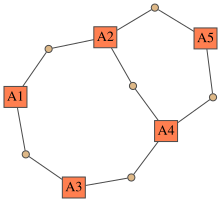

MRF{nodes: 5, edges: 6, domainSize: 32, dim: 24}
Variables: {'A3', 'A5', 'A2', 'A4', 'A1'}
Edges: {(0, 1), (3, 4), (1, 4), (2, 3), (0, 2), (1, 3)}


In [25]:
# Create the Markov network
mn = gum.fastMRF(
    "A1--A2; A1--A3; A2--A4; A2--A5; A3--A4; A4--A5"
)

# Display the graph
gnb.showMRF(mn)

# Print the network structure
print(mn)
print("Variables:", mn.names())
print("Edges:", mn.edges())

The Markov network was created and visualized using the `pyAgrum` library. The graph contains five binary variables and six edges, corresponding to the connections specified in the exercise.

The maximal cliques of the network are:

- \(C_1 = \{A_1,A_2\}\)
- \(C_2 = \{A_1,A_3\}\)
- \(C_3 = \{A_2,A_4,A_5\}\)
- \(C_4 = \{A_3,A_4\}\)

These are the maximal cliques because no additional variable can be added to any of these sets while preserving the property that every pair of variables in the set is connected.

## Part (b): Joint Probability Distribution

The exercise defines a potential function for each maximal clique.

The joint probability is obtained by multiplying the clique potentials and normalizing the result so that the probabilities of all configurations add up to 1.

Since there are five binary variables, there are 32 possible configurations.

We calculate the probability of every configuration and identify the one or more configurations with the highest probability.

In [29]:
# Generate all 32 binary configurations
configurations = list(itertools.product([0, 1], repeat=5))

# Define the edges of the Markov network
edges = [
    ("A1", "A2"),
    ("A1", "A3"),
    ("A2", "A4"),
    ("A2", "A5"),
    ("A3", "A4"),
    ("A4", "A5")
]

# Convert variable names into indices
edge_indices = [
    (int(u[1:]) - 1, int(v[1:]) - 1)
    for u, v in edges
]

# Choose a positive beta value for this example
beta = 0.5

def calculate_score(configuration, beta):
    interaction_sum = sum(
        configuration[i] * configuration[j]
        for i, j in edge_indices
    )
    return np.exp(beta * interaction_sum)

# Calculate the score of each configuration
scores = np.array([
    calculate_score(configuration, beta)
    for configuration in configurations
])

# Normalize the scores to obtain joint probabilities
probabilities = scores / scores.sum()

# Display the joint probability distribution
print("Joint Probability Distribution (beta =", beta, ")")
print("-" * 65)
print(" A1  A2  A3  A4  A5  |  Probability")
print("-" * 65)

for configuration, probability in zip(configurations, probabilities):
    values = "  ".join(map(str, configuration))
    print(f" {values}  |  {probability:.6f}")


print("Number of configurations:", len(configurations))
print("Sum of probabilities:", probabilities.sum())

Joint Probability Distribution (beta = 0.5 )
-----------------------------------------------------------------
 A1  A2  A3  A4  A5  |  Probability
-----------------------------------------------------------------
 0  0  0  0  0  |  0.010326
 0  0  0  0  1  |  0.010326
 0  0  0  1  0  |  0.010326
 0  0  0  1  1  |  0.017024
 0  0  1  0  0  |  0.010326
 0  0  1  0  1  |  0.010326
 0  0  1  1  0  |  0.017024
 0  0  1  1  1  |  0.028068
 0  1  0  0  0  |  0.010326
 0  1  0  0  1  |  0.017024
 0  1  0  1  0  |  0.017024
 0  1  0  1  1  |  0.046276
 0  1  1  0  0  |  0.010326
 0  1  1  0  1  |  0.017024
 0  1  1  1  0  |  0.028068
 0  1  1  1  1  |  0.076297
 1  0  0  0  0  |  0.010326
 1  0  0  0  1  |  0.010326
 1  0  0  1  0  |  0.010326
 1  0  0  1  1  |  0.017024
 1  0  1  0  0  |  0.017024
 1  0  1  0  1  |  0.017024
 1  0  1  1  0  |  0.028068
 1  0  1  1  1  |  0.046276
 1  1  0  0  0  |  0.017024
 1  1  0  0  1  |  0.028068
 1  1  0  1  0  |  0.028068
 1  1  0  1  1  |  0.076297
 1 

In [27]:
# Find the maximum probability
max_probability = probabilities.max()

# Find all configurations attaining the maximum
max_configurations = [
    configurations[i]
    for i, probability in enumerate(probabilities)
    if np.isclose(probability, max_probability)
]

print("Beta:", beta)
print("Maximum probability:", max_probability)
print("Most probable configuration(s):")

for configuration in max_configurations:
    print(configuration)

Beta: 0.5
Maximum probability: 0.20739675659944423
Most probable configuration(s):
(1, 1, 1, 1, 1)


### Results and Interpretation

The probability distribution contains 32 configurations, and the sum of all probabilities is 1.

For the selected positive value of beta, the configuration in which all variables equal 1 has the highest probability.

This happens because the original potential functions reward pairs of connected variables when both variables have the value 1.

The result depends on the value of beta. The value used here is an example because the exercise does not specify a numerical value.

## Part (c): Modification for the Ising Model

In the original model, the potential functions favor connected pairs when both variables equal 1.

To obtain the Ising model, we modify the potential functions so that neighboring variables are rewarded whenever they have the same value, whether both are 0 or both are 1.

We can do this by transforming each binary variable into a spin variable:

- A value of 0 becomes -1.
- A value of 1 becomes +1.

The modified potential rewards neighboring variables with the same spin when beta is positive.

Consequently, both the all-zero configuration and the all-one configuration are favored. This is different from the original model, which specifically rewards neighboring pairs of ones.

In [28]:
def calculate_ising_score(configuration, beta):
    """
    Calculate the Ising score using spin values -1 and +1.
    """
    spins = 2 * np.array(configuration) - 1

    interaction_sum = sum(
        spins[i] * spins[j]
        for i, j in edge_indices
    )

    return np.exp(beta * interaction_sum)


# Calculate and normalize the Ising scores
ising_scores = np.array([
    calculate_ising_score(configuration, beta)
    for configuration in configurations
])

ising_probabilities = ising_scores / ising_scores.sum()

# Find all configurations with maximum probability
ising_max_probability = ising_probabilities.max()

ising_max_configurations = [
    configurations[i]
    for i, probability in enumerate(ising_probabilities)
    if np.isclose(probability, ising_max_probability)
]

print("Ising model with beta =", beta)
print("Sum of probabilities:", ising_probabilities.sum())
print("Maximum probability:", ising_max_probability)
print("Most probable configurations:")

for configuration in ising_max_configurations:
    print(configuration)

Ising model with beta = 0.5
Sum of probabilities: 1.0
Maximum probability: 0.2619877260320614
Most probable configurations:
(0, 0, 0, 0, 0)
(1, 1, 1, 1, 1)
